# Segmentación + clasificación de alimentos en FoodSeg103 (versión final)

**SegFormer-B1 (segmentador) + cabeza de clasificación por región sobre embeddings de CLIP**

Este notebook contiene **todo el flujo en un solo archivo**: entrena el segmentador, extrae los embeddings, entrena la cabeza de clasificación, evalúa y deja una función de inferencia lista para usar. **No lee ni necesita checkpoints ni archivos de caché**: todo se calcula y vive en memoria durante la ejecución (al final hay una celda opcional que *exporta* los modelos, pero el notebook nunca los vuelve a leer).

## Resumen en 30 segundos

- **Problema:** dada una foto de comida, obtener *qué alimentos hay y en qué píxeles están* (segmentación semántica a nivel de ingrediente, 103 clases de FoodSeg103 + fondo).
- **Hallazgo principal:** un segmentador pequeño (SegFormer-B1) dibuja bien *dónde* hay comida (IoU de primer plano ≈ 0.92) pero **se equivoca mucho en *qué* es cada región** (mIoU ≈ 0.27). Por eso se añade una cabeza que **reclasifica cada región** usando embeddings de CLIP-L/14 entrenados sobre recortes de la región.
- **Resultado (validación, mIoU a 1/4 de resolución):** B1 solo ≈ **0.266** → B1 + cabeza CLIP ≈ **0.385**.
- **Qué NO resuelve:** si el segmentador funde dos alimentos en una sola región (o parte uno en dos), la cabeza no lo corrige, porque solo cambia la etiqueta de regiones ya dibujadas. Ese es el límite actual y se ataca con un mejor segmentador o con fine-tuning.

## Índice

0. Contexto, glosario y cómo ejecutar
1. Configuración y datos
2. **Parte A:** entrenar el segmentador (SegFormer-B1)
3. **Parte B:** cabeza de clasificación con CLIP (entrenada sobre regiones ground truth)
4. **Parte C:** pipeline completo sobre regiones *predichas* y evaluación (mIoU)
5. **Parte D:** función de inferencia `analyze_image` y demo
6. Resultados de referencia, limitaciones y próximos pasos
7. (Opcional) Exportar modelos

## 0. Contexto, glosario y cómo ejecutar

### Contexto del proyecto
El objetivo general es una app que estime calorías y macronutrientes a partir de una foto de comida. El pipeline completo previsto es: **segmentar** cada alimento → **clasificar** cada región → estimar **gramos** (con profundidad, parte que desarrolla otra persona del equipo usando Nutrition5k) → consultar una tabla nutricional. **Este notebook cubre solo la parte de segmentar + clasificar, con FoodSeg103.** El ajuste (fine-tuning) al dominio de Nutrition5k (fotos cenitales de bandejas de cafetería) es una etapa posterior y no está aquí.

### Arquitectura
```
foto ──► SegFormer-B1 ──► mapa de clases por píxel (104 ids: 0 = fondo, 1..103 = alimentos)
                              │
                              ▼
           partir cada clase predicha en componentes conectados  ──►  REGIONES
                              │
                              ▼
      por cada región: recorte "masked" + recorte "bbox" ──► CLIP-L/14 ──► embedding (promedio de ambos)
                              │
                              ▼
         cabeza lineal (103 clases, inicializada con el texto de CLIP) ──► clase + probabilidad
                              │
                              ▼
  si prob >= TAU: la región toma la clase de la cabeza; si no, conserva la clase de B1
```

### Glosario (para leer el resto del notebook)
- **Región ground truth (GT):** componente conectado de una clase en la máscara anotada del dataset. Se usa solo para *entrenar y medir la cabeza*.
- **Región predicha:** componente conectado de una clase en la predicción de B1. Es lo que existe en producción.
- **Recorte `masked`:** recorte de la caja que rodea la región, con todo lo que queda fuera de la máscara pintado de gris. Aísla el alimento pero pierde contexto.
- **Recorte `bbox`:** el mismo recorte pero sin enmascarar (con contexto: plato, vecinos).
- **Embedding `avg`:** promedio normalizado de los embeddings de `masked` y `bbox`. Es la variante que mejor funcionó: ambos recortes se complementan.
- **Cabeza "init texto":** una capa lineal cuyos pesos iniciales son los embeddings de texto de CLIP de cada clase (por eso, antes de entrenar, ya funciona como clasificador *zero-shot*). Luego se afina con datos.
- **TAU (τ):** umbral de confianza de la cabeza. Con τ = 0.3, la región solo cambia de clase si la cabeza tiene probabilidad ≥ 0.3.
- **mIoU:** promedio, sobre clases, de intersección / unión. **En este notebook se mide a 1/4 de la resolución de entrada de B1 (128×128 si la entrada es 512×512), ignorando píxeles con etiqueta 255, e incluyendo el fondo.** Este protocolo es el que se usó en todos los experimentos previos del proyecto.
- **Accuracy / recall medio (en regiones GT):** accuracy = % de regiones bien clasificadas; recall medio = recall promediado por clase (premia no ignorar clases raras).

### Cómo ejecutar
1. **Hardware:** se necesita GPU con CUDA (probado en una RTX 5060 con PyTorch 2.11.0+cu128). En CPU el notebook es inviable (CLIP-L/14 sobre miles de regiones y el entrenamiento de B1).
2. **Librerías:** `torch`, `transformers`, `datasets`, `scipy`, `pandas`, `matplotlib`, `tqdm`, `pillow`. Si falta alguna: `pip install transformers datasets scipy pandas matplotlib tqdm pillow`.
3. **Datos:** FoodSeg103 en formato Arrow de Hugging Face. Ajusta `DATA_PATH` en la configuración; si la carpeta no existe, el notebook descarga el dataset del Hub (`EduardoPacheco/FoodSeg103`). También se descargan de Hugging Face los pesos preentrenados `nvidia/mit-b1` (solo el *backbone*; el segmentador se entrena aquí) y `openai/clip-vit-large-patch14` (~1.7 GB).
4. **Prueba rápida:** pon `QUICK = True` en la configuración. Usa un subconjunto pequeño y pocas épocas, solo para comprobar que todo corre; los resultados de ese modo **no son válidos**.
5. **Orden:** ejecutar de arriba abajo. Las partes A y B son independientes entre sí (la cabeza se entrena sobre regiones GT, sin usar B1); la parte C une ambas.
6. **Tiempos orientativos (no medidos en este entorno):** entrenamiento de B1 (15 épocas), del orden de 1 hora; extracción de embeddings CLIP de las regiones GT de train + val, del orden de 20 a 40 minutos; entrenamiento de la cabeza, un par de minutos; evaluación de regiones predichas, unos minutos.
7. **Reproducibilidad:** se fija una semilla, pero los resultados pueden variar ligeramente entre ejecuciones y entre GPUs.

## 1. Configuración y datos
Todos los parámetros ajustables están en la celda siguiente.

In [2]:
import os, re, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from scipy import ndimage
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from datasets import load_from_disk, load_dataset, DatasetDict
from transformers import (CLIPModel, CLIPProcessor, SegformerForSemanticSegmentation,
                          get_cosine_schedule_with_warmup)

# ============================== CONFIGURACIÓN ==============================
QUICK = False                                  # True = prueba rápida de humo (resultados NO válidos)

# --- datos ---
DATA_PATH = r"C:\foodseg103"                   # carpeta Arrow de FoodSeg103; si no existe se descarga del Hub
HUB_NAME  = "EduardoPacheco/FoodSeg103"

# --- parte A: segmentador ---
SEG_BACKBONE    = "nvidia/mit-b1"              # SegFormer-B1 preentrenado en ImageNet (solo el backbone)
INPUT_SIZE      = 512                          # las imágenes se redimensionan a INPUT_SIZE x INPUT_SIZE
SEG_EPOCHS      = 15
SEG_BATCH       = 8                            # baja a 4 si te quedas sin memoria de GPU
SEG_LR          = 6e-5                         # learning rate del encoder
SEG_HEAD_LR_MULT = 10                          # el decoder usa SEG_LR * este factor
SEG_WD          = 0.01
SEG_WARMUP_STEPS = 300
NUM_WORKERS     = 0                            # en Windows/Jupyter déjalo en 0; en Linux puedes usar 2-4

# --- parte B: cabeza CLIP ---
CLIP_NAME   = "openai/clip-vit-large-patch14"
MIN_AREA_GT = 400                              # área mínima (px, resolución original) de una región GT
PAD         = 10                               # margen (px) alrededor del recorte
CLIP_BATCH  = 64                               # recortes por lote en CLIP
HEAD_EPOCHS = 40
HEAD_LR     = 2e-4
HEAD_WD     = 1e-4
HEAD_BATCH  = 256
HEAD_WPOWER = 0.5                              # pesos por clase = frecuencia^(-HEAD_WPOWER); 0 = sin pesos

# --- parte C/D: pipeline con regiones predichas ---
MIN_FRAC_PRED = 0.002                          # área mínima de una región predicha, como fracción de la imagen
TAU = 0.3                                      # umbral de confianza de la cabeza (ver glosario)

SEED = 0
EXPORT = True                                 # True = la última celda guarda los modelos (el notebook NO los lee)

# ---------------------------------------------------------------------------
if QUICK:
    SEG_EPOCHS, HEAD_EPOCHS, MAX_TRAIN, MAX_VAL = 1, 5, 200, 100
else:
    MAX_TRAIN = MAX_VAL = None

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "SIN GPU (no recomendado)")

torch 2.11.0+cu128 | device: cuda | NVIDIA GeForce RTX 5060 Laptop GPU


### Carga del dataset
FoodSeg103 tiene 7,118 imágenes: 4,983 de entrenamiento y 2,135 de test, que aquí llamamos **validación** (`val_ds`). Cada ejemplo trae la imagen y una máscara donde cada píxel vale el id de la clase (**0 = fondo, 1..103 = alimentos**, 255 = ignorar). La celda detecta automáticamente si los datos están como carpeta Arrow guardada con `save_to_disk`, como subcarpetas por split, o como archivos `.arrow` sueltos.

In [3]:
def load_foodseg():
    p = Path(DATA_PATH)
    if p.is_dir():
        try:
            return load_from_disk(str(p))
        except Exception:
            subs = {}
            for d in p.iterdir():
                if d.is_dir():
                    try:
                        subs[d.name] = load_from_disk(str(d))
                    except Exception:
                        pass
            if subs:
                return DatasetDict(subs)
            files = {}
            for f in p.rglob("*.arrow"):
                key = "train" if "train" in f.name.lower() else ("validation" if any(k in f.name.lower() for k in ["val", "test"]) else None)
                if key:
                    files.setdefault(key, []).append(str(f))
            if files:
                return load_dataset("arrow", data_files=files)
            raise
    print("DATA_PATH no existe; descargando del Hub...")
    return load_dataset(HUB_NAME)

def pick_split(ds, names):
    if isinstance(ds, DatasetDict):
        for n in names:
            if n in ds:
                return ds[n]
        raise KeyError(f"No encuentro ninguno de {names} en {list(ds.keys())}")
    return ds

ds = load_foodseg()
train_ds = pick_split(ds, ["train"])
val_ds   = pick_split(ds, ["validation", "val", "test"])
if QUICK:
    train_ds = train_ds.select(range(MAX_TRAIN)); val_ds = val_ds.select(range(MAX_VAL))

cols = train_ds.column_names
IMG_COL  = next(c for c in ["image", "img"] if c in cols)
MASK_COL = next(c for c in ["label", "mask", "annotation", "segmentation", "labels"] if c in cols)
print("train:", len(train_ds), "| val:", len(val_ds), "| columnas imagen/máscara:", IMG_COL, "/", MASK_COL)

train: 4983 | val: 2135 | columnas imagen/máscara: image / label


### Nombres de las clases
Las 103 clases de FoodSeg103 en el **orden estándar del dataset** (id 1 = `candy`, …, id 103 = `other ingredients`; el id 0 es el fondo). Se definen aquí a mano a propósito: la configuración de algunos checkpoints de SegFormer guarda nombres genéricos (`clase_1`, `clase_2`, …) que **rompen** el clasificador de texto de CLIP (da exactamente resultados de azar). Con esta lista, el zero-shot de CLIP da ≈ 50 % de accuracy, lo que confirma que el orden coincide con los ids de las máscaras.

In [4]:
CLASS_NAMES = ["candy","egg tart","french fries","chocolate","biscuit","popcorn","pudding","ice cream","cheese butter","cake",
 "wine","milkshake","coffee","juice","milk","tea","almond","red beans","cashew","dried cranberries","soy","walnut","peanut","egg",
 "apple","date","apricot","avocado","banana","strawberry","cherry","blueberry","raspberry","mango","olives","peach","lemon","pear",
 "fig","pineapple","grape","kiwi","melon","orange","watermelon","steak","pork","chicken duck","sausage","fried meat","lamb","sauce",
 "crab","fish","shellfish","shrimp","soup","bread","corn","hamburg","pizza","hanamaki baozi","wonton dumplings","pasta","noodles",
 "rice","pie","tofu","eggplant","potato","garlic","cauliflower","tomato","kelp","seaweed","spring onion","rape","ginger","okra",
 "lettuce","pumpkin","cucumber","white radish","carrot","asparagus","bamboo shoots","broccoli","celery stick","cilantro mint",
 "snow peas","cabbage","bean sprouts","onion","pepper","green beans","French beans","king oyster mushroom","shiitake",
 "enoki mushroom","oyster mushroom","white button mushroom","salad","other ingredients"]
K  = len(CLASS_NAMES)          # 103 clases de alimento
NC = K + 1                     # 104 ids contando el fondo (id 0)
assert K == 103
ID2NAME = {0: "background", **{i + 1: n for i, n in enumerate(CLASS_NAMES)}}
NAME2ID = {v: k for k, v in ID2NAME.items()}

### Utilidades comunes
Funciones que se usan en varias partes: lectura de máscaras, extracción de **regiones** (componentes conectados), generación de los dos tipos de recorte (`masked` y `bbox`) y preprocesado de la imagen para B1.

In [5]:
def to_mask(x):
    """Máscara del dataset -> array int32 (H, W)."""
    m = np.array(x)
    if m.ndim == 3:
        m = m[..., 0]
    return m.astype(np.int32)

def connected_regions(class_map, min_area, ignore=(0, 255), max_class=NC - 1):
    """Parte cada clase de `class_map` en componentes conectados.
    Devuelve lista de (id_de_clase, máscara_booleana) con área >= min_area."""
    out = []
    for c in np.unique(class_map):
        if c in ignore or c > max_class:
            continue
        comp, n = ndimage.label(class_map == c)
        if n == 0:
            continue
        areas = np.bincount(comp.ravel())[1:]
        for k in np.where(areas >= min_area)[0] + 1:
            out.append((int(c), comp == k))
    return out

def _bbox(m, shape, pad):
    ys, xs = np.where(m)
    return (max(ys.min() - pad, 0), min(ys.max() + pad, shape[0]),
            max(xs.min() - pad, 0), min(xs.max() + pad, shape[1]))

def crop_masked(img, m, pad=PAD):
    """Recorte de la caja de la región con el exterior de la máscara en gris (aísla el alimento)."""
    y0, y1, x0, x1 = _bbox(m, img.shape, pad)
    crop = img[y0:y1, x0:x1].copy()
    crop[~m[y0:y1, x0:x1]] = 127
    return Image.fromarray(crop)

def crop_bbox(img, m, pad=PAD):
    """Recorte de la caja de la región sin enmascarar (conserva el contexto)."""
    y0, y1, x0, x1 = _bbox(m, img.shape, pad)
    return Image.fromarray(img[y0:y1, x0:x1].copy())

def up_nearest(m_small, H, W):
    """Sube una máscara booleana pequeña a (H, W) con vecino más cercano."""
    return np.array(Image.fromarray(m_small.astype(np.uint8) * 255).resize((W, H), Image.NEAREST)) > 0

# preprocesado de entrada de B1 (idéntico en entrenamiento e inferencia): resize bilineal + normalización ImageNet
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def to_input_tensor(img_pil):
    img = img_pil.convert("RGB").resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float().div(255)
    return (x - _MEAN) / _STD

# sanidad rápida: valores de la máscara y regiones GT de la primera imagen
_ex = train_ds[0]
_img = np.array(_ex[IMG_COL].convert("RGB")); _m = to_mask(_ex[MASK_COL])
print("imagen:", _img.shape, "| ids en la máscara:", np.unique(_m))
for c, m in connected_regions(_m, MIN_AREA_GT):
    print(f"  región GT: {ID2NAME[c]:22s} área={int(m.sum())} px")

imagen: (384, 512, 3) | ids en la máscara: [ 0 48 66 90]
  región GT: chicken duck           área=47014 px
  región GT: rice                   área=73227 px
  región GT: snow peas              área=29097 px


## 2. Parte A: entrenar el segmentador (SegFormer-B1)

**Qué hace:** ajusta (fine-tuning) SegFormer-B1 sobre FoodSeg103. Parte del *backbone* `nvidia/mit-b1` preentrenado en ImageNet; el decoder (la cabeza de segmentación de 104 clases) se inicializa desde cero, por lo que Hugging Face avisará de pesos "newly initialized": es lo esperado.

**Receta de entrenamiento (cada decisión):**
- Imágenes y máscaras redimensionadas a 512×512 (bilineal para la imagen, vecino más cercano para la máscara).
- Aumentos simples: volteo horizontal y variación aleatoria de brillo y contraste (solo en entrenamiento).
- AdamW; learning rate 6e-5 en el encoder y 10× en el decoder (práctica habitual en SegFormer, el decoder parte de cero); calentamiento de 300 pasos y decaimiento coseno.
- Pérdida de entropía cruzada que calcula el propio modelo (sube los logits a 512×512 y **ignora los píxeles 255**).
- Precisión mixta bfloat16 y recorte de gradiente (norma 1.0).
- **No se hace selección de modelo con validación**: se entrena un número fijo de épocas y se usa el modelo final.

**Importante:** la receta exacta (aumentos, learning rates) del modelo con el que se obtuvieron los números de referencia de la sección 6 podría diferir ligeramente de esta. Si el mIoU de B1 aquí difiere algo de ≈ 0.27, esa es la explicación más probable, y la cabeza de la parte B es independiente de B1.

In [6]:
class SegTrainDataset(Dataset):
    """Devuelve (imagen normalizada 3xSxS, máscara SxS int64) con aumentos simples si train=True."""
    def __init__(self, hf_ds, train):
        self.ds, self.train = hf_ds, train
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[int(i)]
        img = ex[IMG_COL].convert("RGB").resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)
        lab = Image.fromarray(to_mask(ex[MASK_COL]).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.NEAREST)
        if self.train:
            if random.random() < 0.5:
                img, lab = img.transpose(Image.FLIP_LEFT_RIGHT), lab.transpose(Image.FLIP_LEFT_RIGHT)
            img = ImageEnhance.Brightness(img).enhance(random.uniform(0.8, 1.2))
            img = ImageEnhance.Contrast(img).enhance(random.uniform(0.8, 1.2))
        x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float().div(255)
        x = (x - _MEAN) / _STD
        return x, torch.from_numpy(np.asarray(lab).astype(np.int64))

seg = SegformerForSemanticSegmentation.from_pretrained(
    SEG_BACKBONE, num_labels=NC, id2label=ID2NAME,
    label2id=NAME2ID, ignore_mismatched_sizes=True).to(device)
print("parámetros de B1: %.1f M" % (sum(p.numel() for p in seg.parameters()) / 1e6))

head_params = [p for n, p in seg.named_parameters() if n.startswith("decode_head")]
back_params = [p for n, p in seg.named_parameters() if not n.startswith("decode_head")]
opt = torch.optim.AdamW([{"params": back_params, "lr": SEG_LR},
                         {"params": head_params, "lr": SEG_LR * SEG_HEAD_LR_MULT}], weight_decay=SEG_WD)
train_loader = DataLoader(SegTrainDataset(train_ds, True), batch_size=SEG_BATCH, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=True, pin_memory=(device == "cuda"))
total_steps = SEG_EPOCHS * len(train_loader)
sched = get_cosine_schedule_with_warmup(opt, SEG_WARMUP_STEPS if not QUICK else 5, total_steps)
print(f"{len(train_loader)} pasos por época, {total_steps} pasos en total")

[transformers] You passed `num_labels=104` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 192/192 [00:00<00:00, 21264.46it/s]
[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b1
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.ru

parámetros de B1: 13.7 M
622 pasos por época, 9330 pasos en total


época 1/15: 100%|██████████| 622/622 [05:30<00:00,  1.88it/s]


época 1: pérdida media = 1.9116  (5.5 min acumulados)


época 2/15: 100%|██████████| 622/622 [04:57<00:00,  2.09it/s]


época 2: pérdida media = 1.0397  (10.5 min acumulados)


época 3/15: 100%|██████████| 622/622 [04:55<00:00,  2.11it/s]


época 3: pérdida media = 0.8653  (15.4 min acumulados)


... (20 outputs left out)

época 14/15: 100%|██████████| 622/622 [04:06<00:00,  2.53it/s]


época 14: pérdida media = 0.2742  (63.4 min acumulados)


época 15/15: 100%|██████████| 622/622 [04:05<00:00,  2.54it/s]


época 15: pérdida media = 0.2669  (67.5 min acumulados)


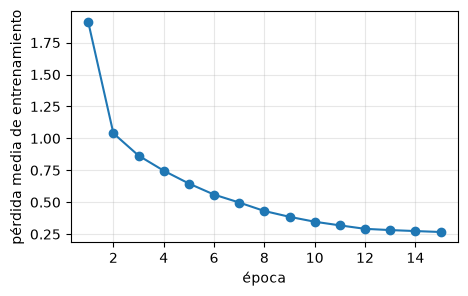

In [7]:
loss_history, t0 = [], time.time()
for ep in range(SEG_EPOCHS):
    seg.train()
    running, n_batches = 0.0, 0
    for x, y in tqdm(train_loader, desc=f"época {ep + 1}/{SEG_EPOCHS}"):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
            loss = seg(pixel_values=x, labels=y).loss
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(seg.parameters(), 1.0)
        opt.step(); sched.step()
        running += loss.item(); n_batches += 1
    loss_history.append(running / max(n_batches, 1))
    print(f"época {ep + 1}: pérdida media = {loss_history[-1]:.4f}  ({(time.time() - t0) / 60:.1f} min acumulados)")
seg.eval()

plt.figure(figsize=(5, 3)); plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("época"); plt.ylabel("pérdida media de entrenamiento"); plt.grid(alpha=.3); plt.show()

La evaluación del segmentador (mIoU) se hace en la **parte C**, junto con el pipeline completo, para que B1 solo y B1 + cabeza se midan exactamente con el mismo código y se puedan comparar.

## 3. Parte B: cabeza de clasificación con CLIP

**Idea:** en lugar de pedirle a B1 que además de dibujar la región decida bien su clase, se toma cada región, se recorta y se le pregunta a CLIP-L/14 (un modelo visión-lenguaje preentrenado con cientos de millones de pares imagen-texto, que reconoce comida muy bien). Sobre los embeddings de CLIP se entrena una capa lineal pequeña. Ventajas: es barata de entrenar (minutos), no depende de B1 ni de su dominio, y añadir una clase nueva es añadir su texto.

**Cómo se entrena (importante para no confundirse):** la cabeza se entrena sobre **regiones ground truth** (componentes conectados de las máscaras anotadas, área ≥ `MIN_AREA_GT` px). Así aprende sobre etiquetas limpias. En la parte C se aplica sobre regiones *predichas* por B1.

**Pasos de esta parte:**
1. Cargar CLIP y definir cómo se calculan los embeddings de imagen y de texto.
2. Extraer los embeddings (`masked` y `bbox`) de todas las regiones GT de train y val.
3. Medir el **zero-shot** (CLIP sin entrenar, comparando contra el texto "a photo of {clase}").
4. Entrenar la cabeza **lineal inicializada con el texto de CLIP** sobre embeddings `avg`, con pérdida ponderada por clase.
5. Medir la cabeza en regiones GT de val.

In [8]:
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
if device == "cuda":
    clip_model = clip_model.half()              # fp16: ~2x más rápido y menos memoria
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)

def _as_tensor(o):
    """Compatibilidad entre versiones de transformers: get_*_features puede devolver tensor u objeto."""
    if torch.is_tensor(o):
        return o
    for a in ("image_embeds", "text_embeds", "pooler_output"):
        if getattr(o, a, None) is not None:
            return getattr(o, a)
    return o[0]

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1)
CLIP_STD  = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1)

def _clip_prep(img, size=224):
    """Mismo preprocesado que CLIP (resize bicúbico + recorte central 224); la normalización se hace en GPU."""
    w, h = img.size
    s = size / min(w, h)
    img = img.resize((max(size, round(w * s)), max(size, round(h * s))), Image.Resampling.BICUBIC)
    w, h = img.size
    l, t = (w - size) // 2, (h - size) // 2
    return np.asarray(img.crop((l, t, l + size, t + size)))

@torch.no_grad()
def embed_images(crops, chunk=128):
    """Lista de PIL -> array (n, 768) de embeddings CLIP normalizados (norma 1)."""
    out = []
    for i in range(0, len(crops), chunk):
        x = torch.from_numpy(np.stack([_clip_prep(c) for c in crops[i:i + chunk]])).to(device).permute(0, 3, 1, 2).float() / 255
        x = ((x - CLIP_MEAN) / CLIP_STD).to(clip_model.dtype)
        e = _as_tensor(clip_model.get_image_features(pixel_values=x))
        out.append(F.normalize(e.float(), dim=-1).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, 768), np.float32)

# Texto de cada clase: promedio de 3 plantillas. PROMPT_FIX reemplaza nombres del dataset poco naturales para CLIP.
TEMPLATES = ["a photo of {}, a type of food.", "a close-up photo of {}.", "a photo of {} in a meal."]
PROMPT_FIX = {"hamburg": "hamburger", "rape": "chinese greens", "hanamaki baozi": "steamed bun",
              "cilantro mint": "cilantro or mint leaves", "cheese butter": "cheese or butter",
              "chicken duck": "chicken or duck meat", "other ingredients": "assorted food ingredients"}

@torch.no_grad()
def build_text_matrix(names):
    """Matriz (K, 768) con el embedding de texto normalizado de cada clase."""
    rows = []
    for n in names:
        n = PROMPT_FIX.get(n, n)
        inp = clip_proc(text=[t.format(n) for t in TEMPLATES], return_tensors="pt", padding=True).to(device)
        e = F.normalize(_as_tensor(clip_model.get_text_features(**inp)).float(), dim=-1).mean(0)
        rows.append(F.normalize(e, dim=-1))
    return torch.stack(rows).cpu().numpy()

TEXT = build_text_matrix(CLASS_NAMES)
print("matriz de texto:", TEXT.shape)

def l2(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

Loading weights: 100%|██████████| 590/590 [00:01<00:00, 374.59it/s]


matriz de texto: (103, 768)


### Extracción de embeddings de las regiones GT
Para cada imagen se obtienen sus regiones GT (en el espacio de etiqueta `id - 1`, es decir 0..102) y, por cada una, el embedding del recorte `masked` y del recorte `bbox`. Se guarda también el área de cada región (para la accuracy ponderada por área). **Es el paso más lento de esta parte y no se guarda en disco.**

In [9]:
def extract_gt_embeddings(split_ds, desc):
    buf_m, buf_b, meta = [], [], []
    E_m, E_b, M = [], [], []
    def flush():
        if meta:
            E_m.append(embed_images(buf_m)); E_b.append(embed_images(buf_b)); M.extend(meta)
            buf_m.clear(); buf_b.clear(); meta.clear()
    for i in tqdm(range(len(split_ds)), desc=desc):
        ex = split_ds[i]
        img = np.array(ex[IMG_COL].convert("RGB"))
        mask = to_mask(ex[MASK_COL])
        if mask.shape != img.shape[:2]:
            mask = np.array(Image.fromarray(mask.astype(np.uint8)).resize((img.shape[1], img.shape[0]), Image.NEAREST)).astype(np.int32)
        for cid, m in connected_regions(mask, MIN_AREA_GT):
            buf_m.append(crop_masked(img, m)); buf_b.append(crop_bbox(img, m))
            meta.append((i, cid - 1, int(m.sum())))
            if len(meta) >= CLIP_BATCH:
                flush()
    flush()
    M = np.array(M)
    return dict(emb_masked=np.concatenate(E_m), emb_bbox=np.concatenate(E_b), y=M[:, 1].astype(np.int64), area=M[:, 2].astype(float))

t0 = time.time()
tr = extract_gt_embeddings(train_ds, "regiones GT train")
va = extract_gt_embeddings(val_ds, "regiones GT val")
print(f"regiones GT: train={len(tr['y'])}, val={len(va['y'])} | clases presentes train/val: {len(np.unique(tr['y']))}/{len(np.unique(va['y']))} | {(time.time() - t0) / 60:.1f} min")

# variante final de features: promedio normalizado de masked y bbox
Xtr = l2(tr["emb_masked"] + tr["emb_bbox"]); ytr = tr["y"]
Xva = l2(va["emb_masked"] + va["emb_bbox"]); yva = va["y"]; area_va = va["area"]

regiones GT val: 100%|██████████| 2135/2135 [03:58<00:00,  8.95it/s]


regiones GT: train=27672, val=11669 | clases presentes train/val: 103/103 | 18.6 min


### Métricas y zero-shot
- `acc`: fracción de regiones bien clasificadas.
- `acc_area`: lo mismo pero ponderando cada región por su área (las regiones grandes pesan más).
- `recall_medio`: recall calculado por clase y promediado entre las clases presentes en validación; es la métrica más sensible a las clases raras.

El **zero-shot** clasifica cada región por la similitud de coseno entre su embedding y el texto de cada una de las 103 clases, sin entrenar nada (aquí CLIP no sabe qué clases hay en la imagen; debe elegir entre las 103).

In [10]:
def region_metrics(y, pred, area):
    ok = (y == pred)
    rec = [ok[y == c].mean() for c in range(K) if (y == c).any()]
    return dict(acc=float(ok.mean()), acc_area=float((ok * area).sum() / area.sum()),
                recall_medio=float(np.mean(rec)), n_clases=len(rec))

pred_zs = (Xva @ TEXT.T).argmax(1)
m_zs = region_metrics(yva, pred_zs, area_va)
print("CLIP zero-shot (avg), regiones GT de val:", {k: round(v, 3) for k, v in m_zs.items()})

CLIP zero-shot (avg), regiones GT de val: {'acc': 0.502, 'acc_area': 0.575, 'recall_medio': 0.486, 'n_clases': 103}


### Entrenamiento de la cabeza lineal con inicialización de texto
- **Modelo:** una sola capa lineal `nn.Linear(768, 103)`. Sus pesos iniciales son los embeddings de texto (multiplicados por 100, la escala de logits de CLIP), de modo que **arranca exactamente en el zero-shot** y el entrenamiento solo lo afina. En experimentos previos esta inicialización dio ≈ 3 puntos más de recall medio que arrancar con pesos aleatorios, con la misma accuracy.
- **Entrada:** el embedding `avg` escalado por √768 para que la optimización sea estable (el escalado de los pesos iniciales lo compensa).
- **Pérdida:** entropía cruzada con **pesos por clase** `frecuencia^(-0.5)`, normalizados: las clases raras pesan más sin llegar a igualarse con las comunes.
- **Optimización:** AdamW con decaimiento coseno, 40 épocas; sin validación para elegir época (número fijo).

In [11]:
def train_linear_head(X, y, text_matrix, epochs=HEAD_EPOCHS, lr=HEAD_LR, wd=HEAD_WD,
                      wpower=HEAD_WPOWER, bs=HEAD_BATCH, seed=SEED):
    torch.manual_seed(seed)
    D = X.shape[1]; s = float(np.sqrt(D))
    Xt = torch.tensor(X * s, dtype=torch.float32, device=device)
    yt = torch.tensor(y, dtype=torch.long, device=device)
    net = nn.Linear(D, K).to(device)
    with torch.no_grad():                                     # inicialización con el texto de CLIP
        net.weight.copy_(torch.tensor(text_matrix, dtype=torch.float32) * (100.0 / s)); net.bias.zero_()
    cnt = np.bincount(y, minlength=K).astype(float)
    w = np.where(cnt > 0, np.maximum(cnt, 1.0) ** (-wpower), 0.0)
    w = w / w[cnt > 0].mean()
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    n = len(Xt)
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = crit(net(Xt[idx]), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return net.eval()

HEAD_DIM = Xtr.shape[1]
head = train_linear_head(Xtr, ytr, TEXT)

@torch.no_grad()
def head_probs_from_avg(X):
    """Embeddings avg (n, 768) -> probabilidades (n, 103)."""
    xt = torch.tensor(X * np.sqrt(HEAD_DIM), dtype=torch.float32, device=device)
    return head(xt).softmax(1).cpu().numpy()

pred_head = head_probs_from_avg(Xva).argmax(1)
m_head = region_metrics(yva, pred_head, area_va)
print("Cabeza entrenada, regiones GT de val:", {k: round(v, 3) for k, v in m_head.items()})
pd.DataFrame([dict(config="CLIP zero-shot (avg)", **m_zs), dict(config="Cabeza lineal init texto (avg)", **m_head)]).round(3)

Cabeza entrenada, regiones GT de val: {'acc': 0.672, 'acc_area': 0.758, 'recall_medio': 0.593, 'n_clases': 103}


,config,acc,acc_area,recall_medio,n_clases
0,CLIP zero-shot (avg),0.502,0.575,0.486,103
1,Cabeza lineal init texto (avg),0.672,0.758,0.593,103


### Recall por clase: dónde ayuda entrenar la cabeza
Compara, clase por clase, el zero-shot contra la cabeza entrenada. Sirve para ver qué clases se benefician del entrenamiento y cuáles siguen siendo difíciles (típicamente las muy raras o ambiguas, como `other ingredients`).

In [12]:
rows_c = []
for c in range(K):
    mk = yva == c
    if mk.any():
        rows_c.append(dict(clase=CLASS_NAMES[c], n_val=int(mk.sum()), n_train=int((ytr == c).sum()),
                           zero_shot=float((pred_zs[mk] == c).mean()), cabeza=float((pred_head[mk] == c).mean())))
percls = pd.DataFrame(rows_c); percls["mejora"] = percls["cabeza"] - percls["zero_shot"]
print("Clases más débiles con la cabeza entrenada:")
display(percls.sort_values("cabeza").head(12).round(2))
print("Clases donde más ayuda entrenar:")
display(percls.sort_values("mejora", ascending=False).head(8).round(2))

Clases más débiles con la cabeza entrenada:


,clase,n_val,n_train,zero_shot,cabeza,mejora
6,pudding,1,5,0.00,0.00,0.00
99,oyster mushroom,4,11,0.00,0.00,0.00
85,bamboo shoots,7,7,0.29,0.00,-0.29
101,salad,11,12,0.00,0.00,0.00
96,king oyster mushroom,3,12,0.33,0.00,-0.33
73,kelp,3,4,0.33,0.00,-0.33
102,other ingredients,103,214,0.00,0.06,0.06
61,hanamaki baozi,12,22,0.17,0.17,0.00
22,peanut,20,16,0.00,0.20,0.20
8,cheese butter,188,421,0.17,0.22,0.05


Clases donde más ayuda entrenar:


,clase,n_val,n_train,zero_shot,cabeza,mejora
94,green beans,99,220,0.03,0.79,0.76
19,dried cranberries,37,68,0.11,0.70,0.59
20,soy,17,35,0.06,0.59,0.53
64,noodles,118,283,0.14,0.67,0.53
7,ice cream,369,841,0.08,0.61,0.52
12,coffee,61,136,0.38,0.89,0.51
66,pie,212,488,0.07,0.55,0.49
30,cherry,135,440,0.20,0.65,0.45


## 4. Parte C: pipeline completo sobre regiones *predichas* y evaluación

Aquí se une todo y se mide lo que importa en producción: **B1 segmenta, la cabeza reclasifica**. Para cada imagen de validación:
1. B1 predice una clase por píxel (salida a 1/4 de la resolución de entrada, es decir 128×128).
2. Cada clase predicha (excepto el fondo) se parte en componentes conectados; se descartan los menores a `MIN_FRAC_PRED` de la imagen. Cada componente es una **región**.
3. Cada región se sube a la resolución original, se generan los recortes `masked` y `bbox`, se calcula su embedding `avg` y la cabeza da una distribución sobre 103 clases.
4. **La clase de la cabeza reemplaza la etiqueta de toda la región** si su probabilidad ≥ `TAU`; si no, la región conserva la clase que le dio B1.

Para poder comparar variantes sin repetir el cálculo pesado, la primera pasada guarda por imagen: GT y predicción de B1 a 1/4 de resolución, el mapa de regiones, la clase de B1 por región y lo que dicen el zero-shot y la cabeza (clase y probabilidad). Después se evalúan todas las variantes sobre lo guardado.

**Protocolo de evaluación (fijo para todas las variantes):** matriz de confusión a 1/4 de resolución (GT reducida con vecino más cercano), ignorando píxeles 255; mIoU = promedio del IoU sobre las clases con unión > 0, **incluyendo el fondo**; se reporta también el mIoU sin fondo y la accuracy por píxel.

In [13]:
@torch.no_grad()
def b1_predict(img_np):
    """Imagen RGB (H, W, 3) uint8 -> mapa de clases de B1 a 1/4 de INPUT_SIZE, int16 (h, w)."""
    x = to_input_tensor(Image.fromarray(img_np)).unsqueeze(0).to(device)
    logits = seg(pixel_values=x).logits                      # (1, 104, h, w); en fp32 a propósito
    return logits.argmax(1)[0].cpu().numpy().astype(np.int16)

def split_regions(pred):
    """Mapa de clases (h, w) -> (regmap uint16 con ids de región 1..n, lista b1 con la clase de B1 de cada región)."""
    h, w = pred.shape
    min_area = max(1, int(MIN_FRAC_PRED * h * w))
    regmap, b1 = np.zeros((h, w), np.uint16), []
    for cid, m in connected_regions(pred, min_area):
        b1.append(cid); regmap[m] = len(b1)
    return regmap, b1

def region_embeddings(img_np, regmap, n):
    """Embeddings `masked` y `bbox` de las regiones 1..n (máscaras subidas a la resolución original)."""
    H, W = img_np.shape[:2]
    cm, cb = [], []
    for r in range(1, n + 1):
        m = up_nearest(regmap == r, H, W)
        cm.append(crop_masked(img_np, m)); cb.append(crop_bbox(img_np, m))
    return embed_images(cm), embed_images(cb)

records, t0 = [], time.time()
for i in tqdm(range(len(val_ds)), desc="val: B1 + regiones + CLIP"):
    ex = val_ds[i]
    img = np.array(ex[IMG_COL].convert("RGB")); H, W = img.shape[:2]
    gt = to_mask(ex[MASK_COL])
    pred = b1_predict(img)
    h, w = pred.shape
    gt_s = np.array(Image.fromarray(gt.astype(np.uint8)).resize((w, h), Image.NEAREST))
    regmap, b1 = split_regions(pred)
    rec = dict(i=i, gt=gt_s, pred=pred, regmap=regmap, b1=np.array(b1, dtype=np.int16))
    if b1:
        em, eb = region_embeddings(img, regmap, len(b1))
        Xavg = l2(em + eb)
        pr = head_probs_from_avg(Xavg)
        rec.update(zs=((Xavg @ TEXT.T).argmax(1) + 1).astype(np.int16),
                   head=(pr.argmax(1) + 1).astype(np.int16), hprob=pr.max(1))
    else:
        rec.update(zs=np.zeros(0, np.int16), head=np.zeros(0, np.int16), hprob=np.zeros(0))
    records.append(rec)
print(f"{len(records)} imágenes, {sum(len(r['b1']) for r in records)} regiones predichas, {(time.time() - t0) / 60:.1f} min")

val: B1 + regiones + CLIP: 100%|██████████| 2135/2135 [07:08<00:00,  4.98it/s]

2135 imágenes, 20265 regiones predichas, 7.1 min


In [14]:
def evaluate(choose):
    """`choose(rec)` devuelve la etiqueta (id 0..103) de cada región de la imagen; se mide el mapa resultante."""
    conf = np.zeros(NC * NC, np.int64)
    for rec in records:
        lab = np.asarray(choose(rec)).astype(np.int16)
        lut = np.concatenate([[0], lab]).astype(np.int16)            # índice 0 (sin región) -> se rellena abajo
        new = np.where(rec["regmap"] > 0, lut[rec["regmap"]], rec["pred"])
        g = rec["gt"].astype(np.int64); v = g < NC                    # ignora 255
        conf += np.bincount(g[v] * NC + new[v].astype(np.int64), minlength=NC * NC)
    conf = conf.reshape(NC, NC)
    tp = np.diag(conf).astype(float)
    union = conf.sum(0) + conf.sum(1) - tp
    iou = np.where(union > 0, tp / np.maximum(union, 1), np.nan)
    return dict(mIoU=float(np.nanmean(iou)), mIoU_sin_fondo=float(np.nanmean(iou[1:])),
                pix_acc=float(tp.sum() / conf.sum())), iou

variants = {
    "B1 solo (baseline)":                       lambda r: r["b1"],
    "CLIP zero-shot reemplaza la región":       lambda r: r["zs"],
    "Cabeza entrenada reemplaza la región":     lambda r: r["head"],
}
for tau in [0.3, 0.5, 0.7, 0.9]:
    variants[f"Cabeza si prob >= {tau}, si no B1"] = lambda r, t=tau: np.where(r["hprob"] >= t, r["head"], r["b1"])

rows, ious = [], {}
for name, fn in variants.items():
    m, iou = evaluate(fn)
    rows.append(dict(config=name, **m)); ious[name] = iou
results = pd.DataFrame(rows)
results.round(4)

,config,mIoU,mIoU_sin_fondo,pix_acc
0,B1 solo (baseline),0.3407,0.3351,0.7813
1,CLIP zero-shot reemplaza la región,0.2673,0.2609,0.7154
2,Cabeza entrenada reemplaza la región,0.3970,0.3919,0.7987
3,"Cabeza si prob >= 0.3, si no B1",0.4113,0.4063,0.8040
4,"Cabeza si prob >= 0.5, si no B1",0.4128,0.4079,0.8037
5,"Cabeza si prob >= 0.7, si no B1",0.4031,0.3981,0.7998
6,"Cabeza si prob >= 0.9, si no B1",0.3864,0.3813,0.7921


**Cómo leer la tabla:** la fila `B1 solo` es la referencia. `CLIP zero-shot reemplaza la región` suele quedar *por debajo* de B1: CLIP sin entrenar no basta para 103 clases. Las filas de la cabeza entrenada son el resultado del método. La variante con `TAU` evita cambiar regiones cuando la cabeza no está segura; con τ muy alto (0.9) casi ninguna región cambia y el beneficio se pierde. Las diferencias entre τ = 0.3, 0.5 y "reemplaza siempre" son pequeñas (menos de 1 punto) y están dentro del ruido de una sola ejecución.

### IoU por clase: dónde gana y dónde pierde el pipeline completo
Compara, para la variante final (`TAU` configurado), el IoU por clase contra B1 solo.

In [15]:
final_name = f"Cabeza si prob >= {TAU}, si no B1"
if final_name not in variants:
    variants[final_name] = lambda r, t=TAU: np.where(r["hprob"] >= t, r["head"], r["b1"])
    m, iou = evaluate(variants[final_name]); ious[final_name] = iou
d = pd.DataFrame({"clase": [ID2NAME[i] for i in range(NC)],
                  "B1_solo": ious["B1 solo (baseline)"], "B1_mas_cabeza": ious[final_name]}).dropna()
d["delta"] = d["B1_mas_cabeza"] - d["B1_solo"]
print("Clases que más mejoran:"); display(d.sort_values("delta", ascending=False).head(12).round(3))
print("Clases que más empeoran:"); display(d.sort_values("delta").head(8).round(3))
print(f"Clases que mejoran: {(d.delta > 0.005).sum()} | empeoran: {(d.delta < -0.005).sum()} | sin cambio relevante: {(d.delta.abs() <= 0.005).sum()}")

Clases que más mejoran:


,clase,B1_solo,B1_mas_cabeza,delta
79,okra,0.050,0.492,0.443
63,wonton dumplings,0.019,0.437,0.418
23,peanut,0.000,0.401,0.401
53,crab,0.108,0.403,0.295
92,bean sprouts,0.197,0.486,0.289
28,avocado,0.212,0.500,0.289
69,eggplant,0.019,0.293,0.273
6,popcorn,0.410,0.682,0.272
36,peach,0.321,0.552,0.231
1,candy,0.104,0.335,0.230


Clases que más empeoran:


,clase,B1_solo,B1_mas_cabeza,delta
2,egg tart,0.464,0.048,-0.416
33,raspberry,0.471,0.409,-0.062
51,lamb,0.251,0.190,-0.061
72,cauliflower,0.544,0.493,-0.051
62,hanamaki baozi,0.098,0.051,-0.047
43,melon,0.176,0.130,-0.046
11,wine,0.256,0.218,-0.038
37,lemon,0.695,0.667,-0.028


Clases que mejoran: 79 | empeoran: 15 | sin cambio relevante: 10


### Ejemplos cualitativos: imagen | ground truth | B1 | B1 + cabeza
Cada color es una clase (los colores son aleatorios pero iguales en las tres columnas de máscara; negro = fondo, blanco = ignorado). Mira especialmente: (1) regiones que B1 fragmenta en varias clases y la cabeza unifica; (2) regiones donde la cabeza corrige a B1; (3) límites del método: alimentos que B1 nunca separó, que la cabeza no puede recuperar.

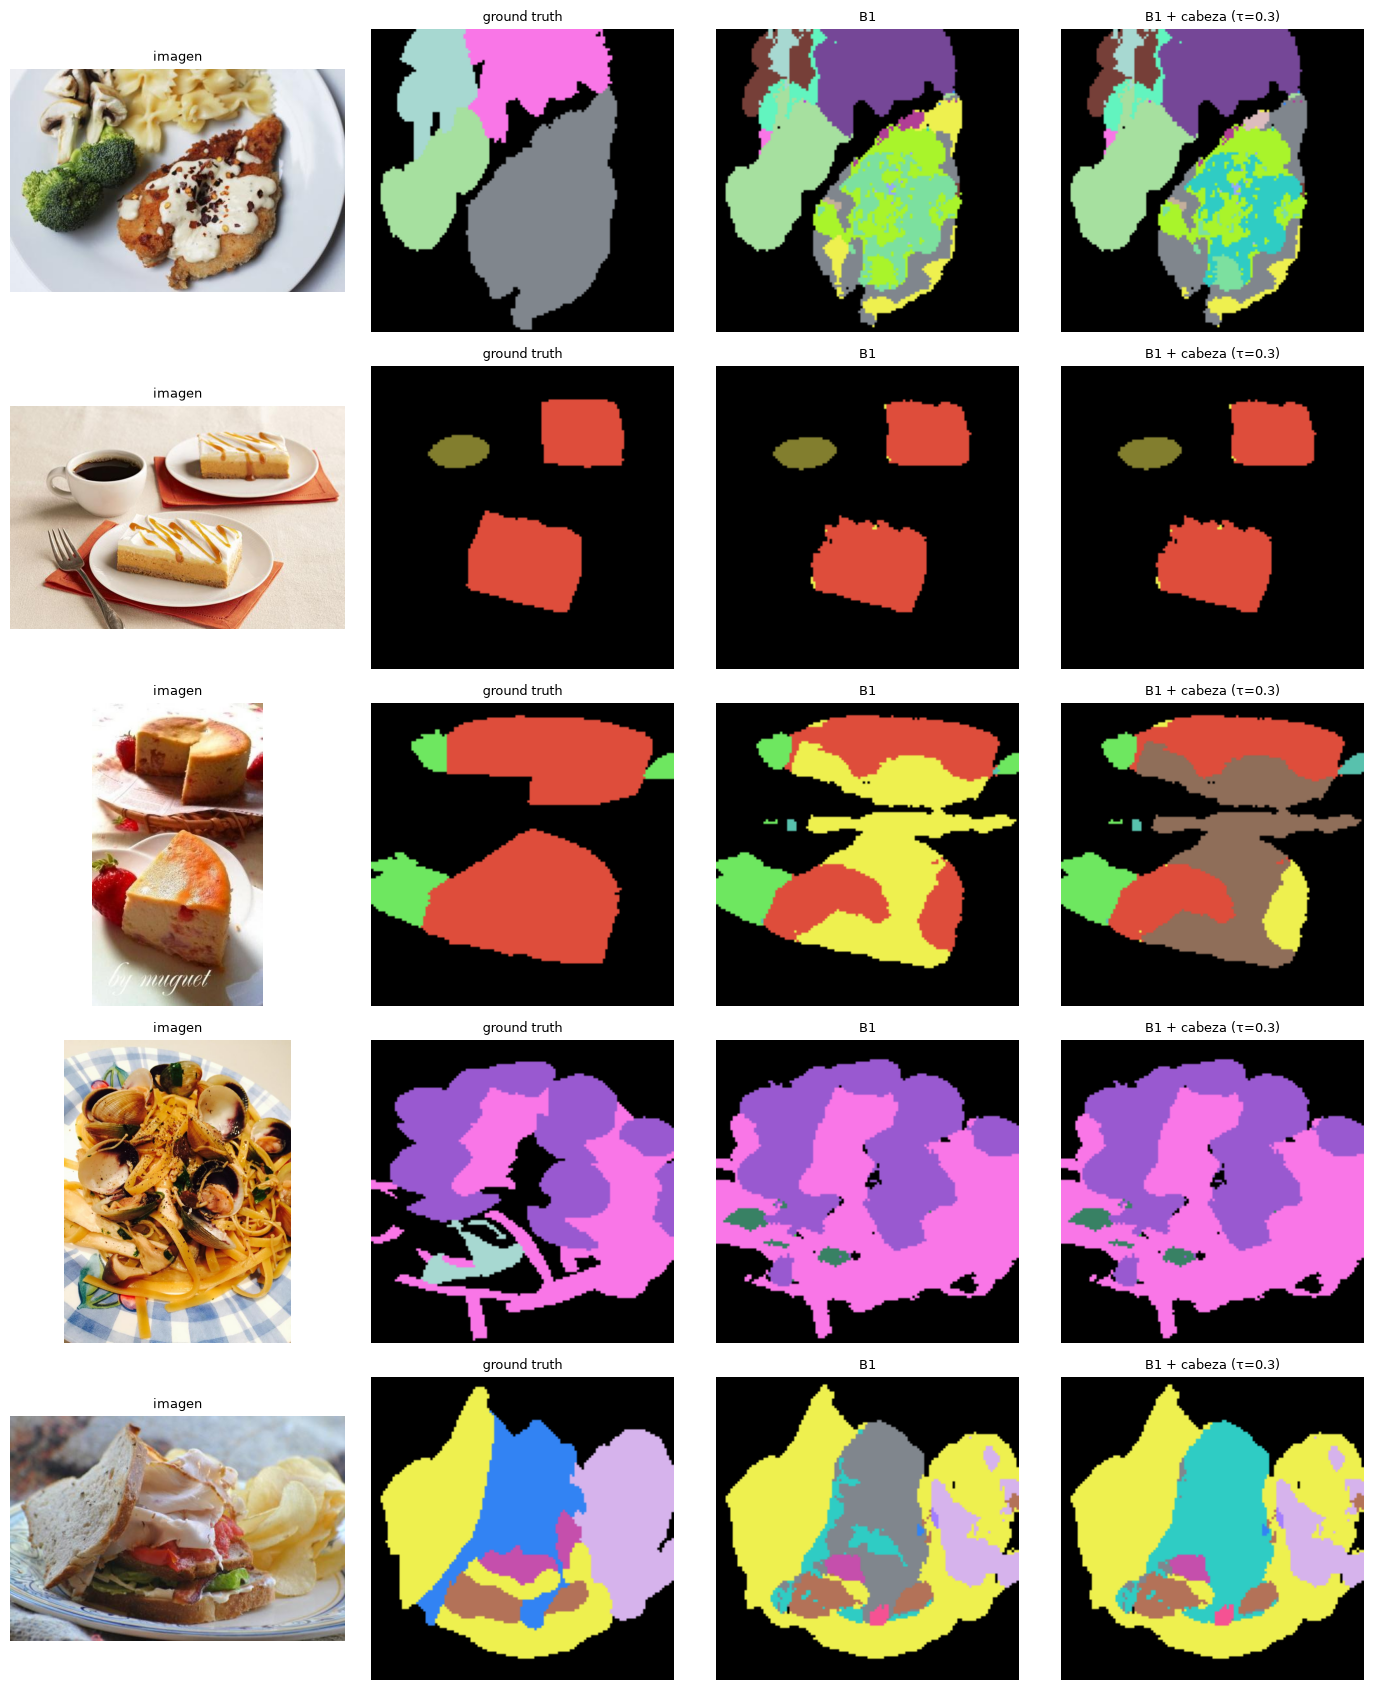

In [16]:
pal = np.zeros((256, 3), np.uint8)
pal[:NC] = np.random.default_rng(0).integers(40, 255, (NC, 3)); pal[0] = 0; pal[255] = 255
paint = lambda lbl: pal[np.clip(lbl, 0, 255).astype(np.uint8)]

def apply_labels(rec, fn):
    lut = np.concatenate([[0], np.asarray(fn(rec)).astype(np.int16)]).astype(np.int16)
    return np.where(rec["regmap"] > 0, lut[rec["regmap"]], rec["pred"])

idx = np.random.default_rng(1).choice(len(records), size=min(5, len(records)), replace=False)
fig, ax = plt.subplots(len(idx), 4, figsize=(14, 3.4 * len(idx))); ax = np.atleast_2d(ax)
for row, j in enumerate(idx):
    rec = records[j]
    ax[row, 0].imshow(val_ds[rec["i"]][IMG_COL].convert("RGB"))
    ax[row, 1].imshow(paint(rec["gt"])); ax[row, 2].imshow(paint(rec["pred"]))
    ax[row, 3].imshow(paint(apply_labels(rec, variants[final_name])))
    for a, t in zip(ax[row], ["imagen", "ground truth", "B1", f"B1 + cabeza (τ={TAU})"]):
        a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Parte D: función de inferencia `analyze_image`

Es la interfaz que deben usar las etapas siguientes del proyecto (estimación de gramos con profundidad, tabla nutricional, demo): recibe **una imagen PIL** y devuelve las regiones detectadas, cada una con su máscara a resolución original, su clase final, la probabilidad de la cabeza y las 3 clases más probables.

Campos de cada región:
- `mask`: máscara booleana (H, W) a resolución original de la imagen.
- `class_id`, `class_name`: clase final (la de la cabeza si `prob >= tau`; si no, la de B1).
- `prob`: probabilidad que asignó la cabeza a su mejor clase (**no** es una probabilidad calibrada; úsala para ordenar o filtrar, no como probabilidad real).
- `source`: `"cabeza"` o `"b1"`, de dónde salió la clase final.
- `b1_class_id`, `b1_class_name`: la clase que había propuesto B1.
- `top_k`: las k clases más probables según la cabeza, como lista de `(nombre, probabilidad)`.
- `area_frac`: fracción de la imagen que ocupa la región.

In [17]:
@torch.no_grad()
def analyze_image(img, tau=TAU, top_k=3):
    """img: PIL.Image. Devuelve dict con 'regions' (lista, ver descripción arriba) y 'foreground_mask' (bool H x W)."""
    img_np = np.array(img.convert("RGB")); H, W = img_np.shape[:2]
    pred = b1_predict(img_np)
    regmap, b1 = split_regions(pred)
    regions = []
    if b1:
        em, eb = region_embeddings(img_np, regmap, len(b1))
        probs = head_probs_from_avg(l2(em + eb))
        for r, (c_b1, p) in enumerate(zip(b1, probs), start=1):
            k = int(p.argmax()); pk = float(p[k]); use_head = pk >= tau
            cid = k + 1 if use_head else int(c_b1)
            mask = up_nearest(regmap == r, H, W)
            top = np.argsort(-p)[:top_k]
            regions.append(dict(mask=mask, class_id=cid, class_name=ID2NAME[cid], prob=pk,
                                source="cabeza" if use_head else "b1",
                                b1_class_id=int(c_b1), b1_class_name=ID2NAME[int(c_b1)],
                                top_k=[(CLASS_NAMES[j], float(p[j])) for j in top],
                                area_frac=float(mask.mean())))
    return dict(regions=regions, foreground_mask=up_nearest(pred != 0, H, W))

### Demo
Aplica `analyze_image` a imágenes de validación y dibuja el contorno de cada región con su clase y probabilidad. La tabla de abajo lista las regiones de la primera imagen (ordenadas por tamaño).

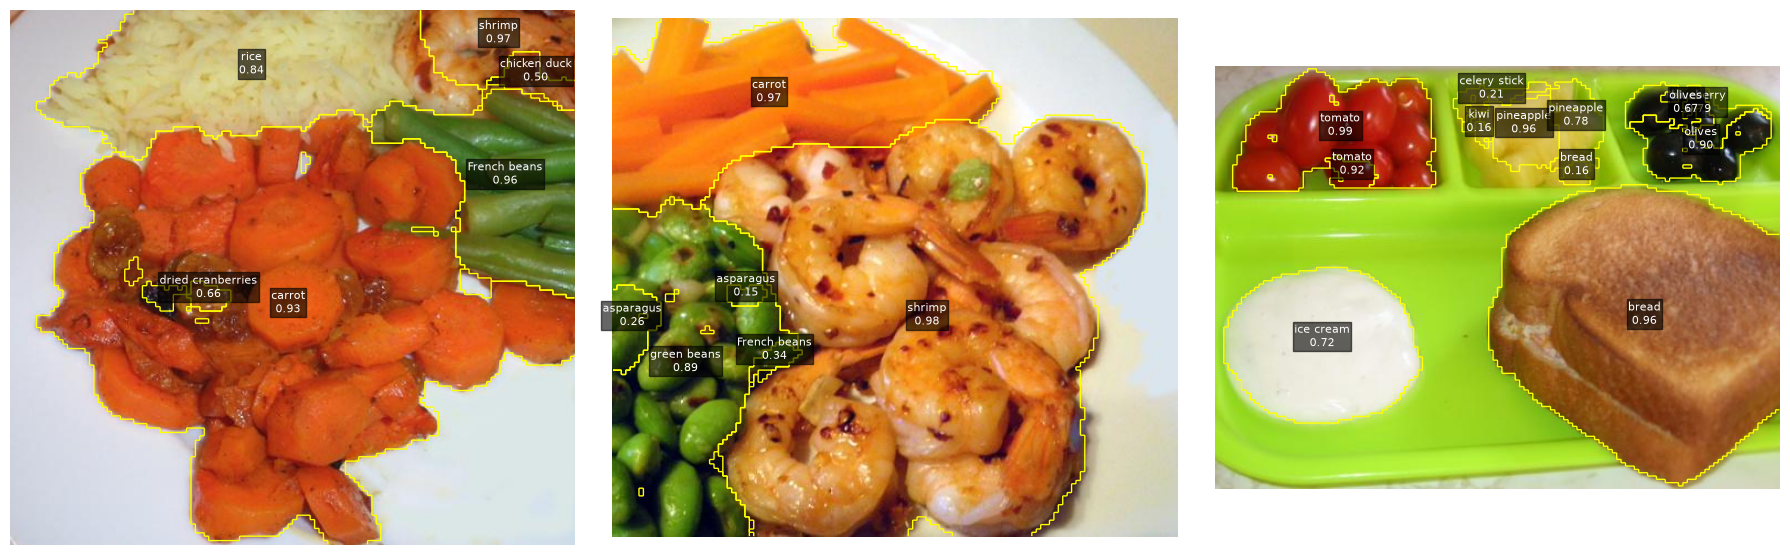

,clase,prob,fuente,clase_B1,area_frac,top3
0,carrot,0.93,cabeza,carrot,0.453,"carrot (0.93), potato (0.03), other ingredient..."
1,rice,0.84,cabeza,rice,0.140,"rice (0.84), carrot (0.04), potato (0.04)"
2,French beans,0.96,cabeza,French beans,0.081,"French beans (0.96), snow peas (0.02), asparag..."
3,shrimp,0.97,cabeza,shrimp,0.032,"shrimp (0.97), chicken duck (0.01), fish (0.00)"
4,chicken duck,0.50,cabeza,chicken duck,0.008,"chicken duck (0.50), pork (0.08), shrimp (0.07)"
5,dried cranberries,0.66,cabeza,soy,0.003,"dried cranberries (0.66), shrimp (0.05), walnu..."


In [18]:
demo_ids = [0, 1, 2] if len(val_ds) > 3 else list(range(len(val_ds)))
fig, ax = plt.subplots(1, len(demo_ids), figsize=(6 * len(demo_ids), 6)); ax = np.atleast_1d(ax)
for a, j in zip(ax, demo_ids):
    img = val_ds[j][IMG_COL].convert("RGB")
    res = analyze_image(img)
    a.imshow(img); a.axis("off")
    for reg in res["regions"]:
        a.contour(reg["mask"], levels=[0.5], colors="yellow", linewidths=1)
        ys, xs = np.where(reg["mask"])
        a.text(xs.mean(), ys.mean(), f'{reg["class_name"]}\n{reg["prob"]:.2f}', color="white", fontsize=8, ha="center",
               bbox=dict(facecolor="black", alpha=0.6, pad=1))
plt.tight_layout(); plt.show()

res0 = analyze_image(val_ds[demo_ids[0]][IMG_COL].convert("RGB"))
pd.DataFrame([dict(clase=r["class_name"], prob=round(r["prob"], 2), fuente=r["source"], clase_B1=r["b1_class_name"],
                   area_frac=round(r["area_frac"], 3), top3=", ".join(f"{n} ({p:.2f})" for n, p in r["top_k"]))
              for r in sorted(res0["regions"], key=lambda r: -r["area_frac"])])

## 6. Resultados de referencia, limitaciones y próximos pasos

### Resultados de referencia (obtenidos en los experimentos previos del proyecto)
Los números siguientes salieron de ejecuciones anteriores (**una sola semilla**, validación de FoodSeg103). Sirven para contrastar con lo que produzca este notebook; es esperable que difieran algo, sobre todo en la parte de B1 (ver sección de la parte A).

**Cabeza sobre regiones ground truth** (accuracy / recall medio por clase; referencia previa: MLP sobre features de B1 = 0.641 / 0.486):

| Configuración | Accuracy | Recall medio |
|---|---|---|
| CLIP zero-shot, `avg` | 0.503 | 0.493 |
| CLIP zero-shot, `masked` solo | 0.433 | 0.405 |
| CLIP zero-shot, `bbox` solo | 0.395 | 0.421 |
| **Lineal init texto, `avg` (la usada aquí)** | **0.673** | **0.595** |
| MLP-512, `avg` | 0.680 | 0.567 |
| Lineal aleatoria, `avg` | 0.671 | 0.565 |
| MLP-512, `concat` (masked ‖ bbox) | 0.688 | 0.555 |
| Lineal init texto, `masked` solo | 0.620 | 0.531 |
| Lineal init texto, `bbox` solo | 0.580 | 0.529 |

Se eligió *lineal init texto + `avg`* por tener el mayor recall medio (el interés es cubrir bien clases poco frecuentes). `concat + MLP` tiene algo más de accuracy pero menos recall.

**Pipeline sobre regiones predichas por B1** (mIoU a 1/4 de resolución, val; referencias previas: baseline 0.2653, cabeza MLP sobre features de B1 0.3209):

| Variante | mIoU | Accuracy por píxel |
|---|---|---|
| B1 solo | 0.2662 | 0.773 |
| CLIP zero-shot reemplaza la región | 0.2534 | 0.711 |
| Cabeza entrenada reemplaza la región | 0.3797 | 0.798 |
| **Cabeza si prob ≥ 0.3, si no B1 (la usada aquí)** | **0.3852** | **0.801** |
| Cabeza si prob ≥ 0.5, si no B1 | 0.3833 | 0.800 |
| Cabeza si prob ≥ 0.7, si no B1 | 0.3715 | 0.798 |
| Cabeza si prob ≥ 0.9, si no B1 | 0.3366 | 0.786 |

### Limitaciones (leer antes de citar los números)
1. **El límite es el segmentador.** La cabeza solo reasigna la clase de regiones que B1 ya dibujó. Si B1 funde dos alimentos en una región o parte uno en varios trozos, el error de contorno se mantiene.
2. **Selección sobre la validación.** La configuración de la cabeza y el valor de τ se eligieron mirando este mismo conjunto de validación. La mejora frente a B1 (+11 puntos de mIoU) es mucho mayor que cualquier sesgo de selección, pero las diferencias pequeñas (p. ej. τ = 0.3 vs 0.5) no son significativas. No hay conjunto de test independiente.
3. **Una sola semilla** en los resultados de referencia; no hay intervalos de confianza.
4. **Comparación con la literatura:** los mIoU publicados de FoodSeg103 se calculan en otro protocolo (resolución completa) y **no son directamente comparables** con los de este notebook (1/4 de resolución, incluye fondo).
5. `prob` de la cabeza no está calibrada.
6. **Dominio:** todo se midió en FoodSeg103 (fotos de la web, ángulos variados). No hay garantía de que el rendimiento se mantenga en otro dominio (p. ej. fotos cenitales de Nutrition5k); esa evaluación está pendiente.

### Próximos pasos
- **Fine-tuning al dominio de Nutrition5k** (fotos cenitales): ajustar B1 con etiquetas generadas automáticamente (SAM2 + CLIP, ver el notebook `Nutrition5k_etiqueted.ipynb`) mezcladas con FoodSeg103 para no olvidar lo aprendido, y ampliar el vocabulario de la cabeza (las clases nuevas pueden iniciarse con su texto de CLIP). Validar solo contra un conjunto **corregido a mano**, nunca contra las etiquetas automáticas.
- **Mejor segmentador:** probar SegFormer-B2/B3 o entrenar B1 más tiempo. La cabeza CLIP no depende de B1, así que cambiar de segmentador solo exige repetir la parte C.
- **Robustez estadística:** repetir el entrenamiento de la cabeza con varias semillas y reportar media ± desviación.
- **Integración:** usar `analyze_image` como entrada de la etapa de gramos (profundidad) y de la tabla nutricional.

## 7. (Opcional) Exportar modelos
Con `EXPORT = True` (en la configuración) esta celda guarda el segmentador y la cabeza para usarlos en otros notebooks o en la app. **Este notebook nunca lee estos archivos**: es solo una salida.

In [19]:
if EXPORT:
    out = Path("export_final"); out.mkdir(exist_ok=True)
    seg.save_pretrained(out / "segformer_b1_foodseg103")
    torch.save({"state_dict": head.state_dict(), "class_names": CLASS_NAMES, "clip_name": CLIP_NAME,
                "features": "avg = normalizar(emb_masked + emb_bbox)", "tau": TAU}, out / "cabeza_clip_lineal.pt")
    print("exportado en", out.resolve())
else:
    print("EXPORT = False: no se guardó nada.")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 20.34it/s]

exportado en C:\Users\mjcor\OneDrive\Desktop\Proyecto IA\export_final
